In [7]:
import torch
import matplotlib.pyplot as plt
import numpy as np

from PIL import Image, ImageDraw, ImageFont
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

from load_model import load_model, preprocess

In [2]:
# Custom target for binary classification
class BinaryClassifierOutputTarget:
    def __init__(self, positive=True):
        self.positive = positive

    def __call__(self, model_output):
        # Assumes the output is a raw logit
        logit = model_output.reshape(-1)[0]

        if self.positive:
            return logit
        else:
            return -logit

## 1. test: Where does a model look

Run all three models on all three images in images/01_compare_models

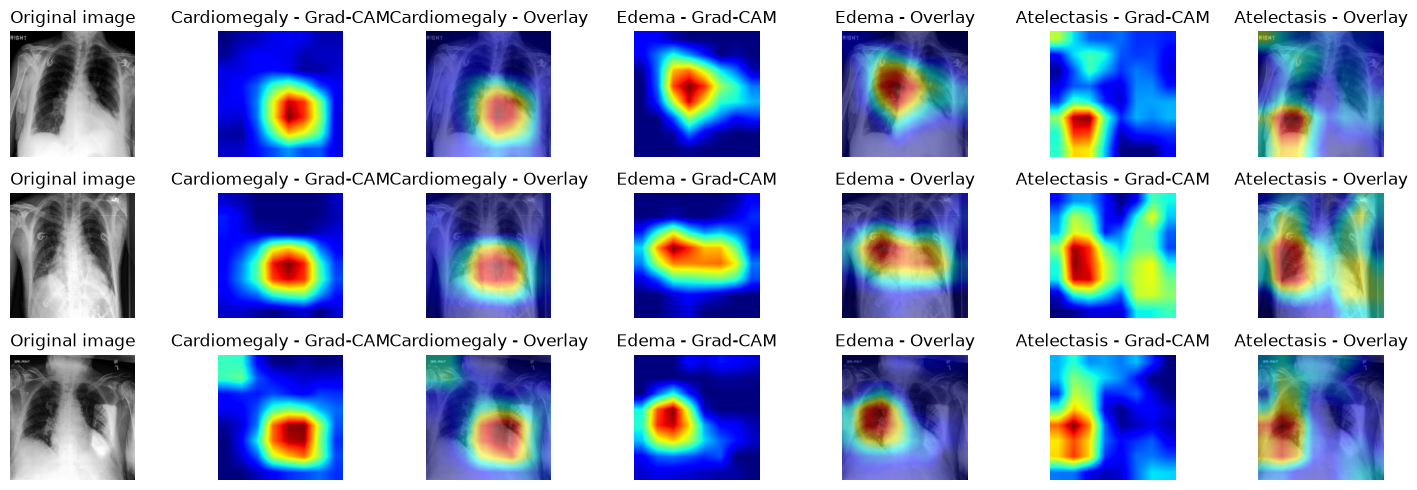

In [5]:
MODELS = ['Cardiomegaly', 'Edema', 'Atelectasis']
IMAGES = ["01_01_original.jpg", "01_02_original.jpg", "01_03_original.jpg"]


fig, axes = plt.subplots(3, 7, figsize=(15, 5))

for ax in axes.flat:
    ax.axis("off")

# Load each model once
models = {m: load_model(m) for m in MODELS}

# Input tensor: shape [1, 3, H, W]
for j, img in enumerate(IMAGES):
    image = Image.open("images/01_compare_models/" + img).convert('RGB')
    x = preprocess(image)

    # Unnormalized RGB image for visualization
    rgb_img = np.asarray(
        image.resize((256, 256), Image.Resampling.BILINEAR),
        dtype=np.float32
    ) / 255.0

    axes[j, 0].imshow(rgb_img)
    axes[j, 0].set_title("Original image")

    col_n = 1

    for m in models:
        model = models[m]
        model.eval()

        # Select the final DenseNet block
        target_layers = [model.features.denseblock4]

        # Generate Grad-CAM
        with GradCAM(model=model,  target_layers=target_layers) as cam:

            grayscale_cam = cam(input_tensor=x, targets=[BinaryClassifierOutputTarget(positive=True)])[0] # shape [H, W]

            visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)
        
            axes[j,col_n].imshow(grayscale_cam, cmap="jet")
            axes[j,col_n].set_title(f"{m} - Grad-CAM")

            col_n += 1

            axes[j,col_n].imshow(visualization)
            axes[j,col_n].set_title(f"{m} - Overlay")

            col_n += 1

plt.tight_layout()
plt.show()


## 2. Positive vs Negative

Use the Cardiomegaly model. Compare the cardiac region and other areas. Images 04 and 06 have explicit No Finding labels; 05 does not.

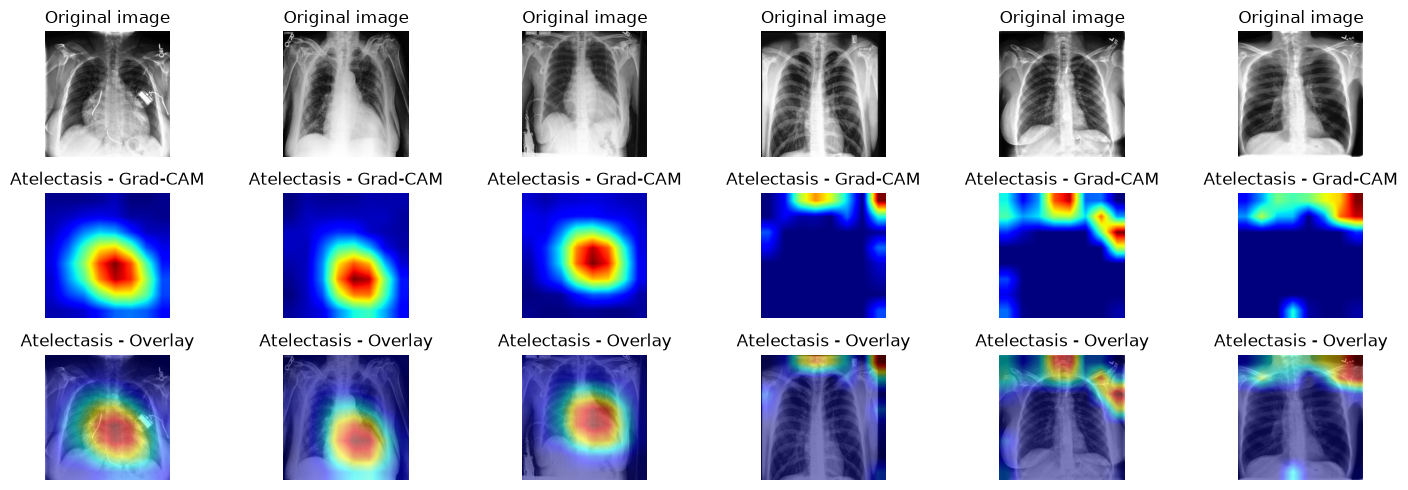

In [6]:
IMAGES2 = ["02_01_original.jpg", "02_02_original.jpg", "02_03_original.jpg", "02_04_original.jpg", "02_05_original.jpg", "02_06_original.jpg"]


fig, axes = plt.subplots(3, 6, figsize=(15, 5))

for ax in axes.flat:
    ax.axis("off")

# Input tensor: shape [1, 3, H, W]
for j, img in enumerate(IMAGES2):
    image = Image.open("images/02_positive_negative/" + img).convert('RGB')
    x = preprocess(image)

    # Unnormalized RGB image for visualization
    rgb_img = np.asarray(
        image.resize((256, 256), Image.Resampling.BILINEAR),
        dtype=np.float32
    ) / 255.0

    axes[0,j].imshow(rgb_img)
    axes[0,j].set_title("Original image")

    col_n = 1

    model = models['Cardiomegaly']
    model.eval()

    # Select the final DenseNet block
    target_layers = [model.features.denseblock4]

    # Generate Grad-CAM
    with GradCAM(model=model,  target_layers=target_layers) as cam:

        grayscale_cam = cam(input_tensor=x, targets=[BinaryClassifierOutputTarget(positive=True)])[0] # shape [H, W]

        visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)
    
        axes[1,j].imshow(grayscale_cam, cmap="jet")
        axes[1,j].set_title(f"{m} - Grad-CAM")

        axes[2,j].imshow(visualization)
        axes[2,j].set_title(f"{m} - Overlay")

plt.tight_layout()
plt.show()

## 3. Text Shortcut

Use the Atelectasis model. Compare each original with its PORTABLE AP version. Add unrelated text of similar size at the same position as a control. Does the effect depend on the words or simply added pixels or s....c..?

In [17]:
# Add text to control images
def add_control_text(image, text="HARRYPOTTER"):
    image = image.copy().convert("RGB")
    draw = ImageDraw.Draw(image)

    font = ImageFont.truetype("C:/Windows/Fonts/arialbd.ttf", 20)

    draw.text(
        (10, 7),
        text,
        fill=(255, 255, 255),
        font=font
    )

    return image

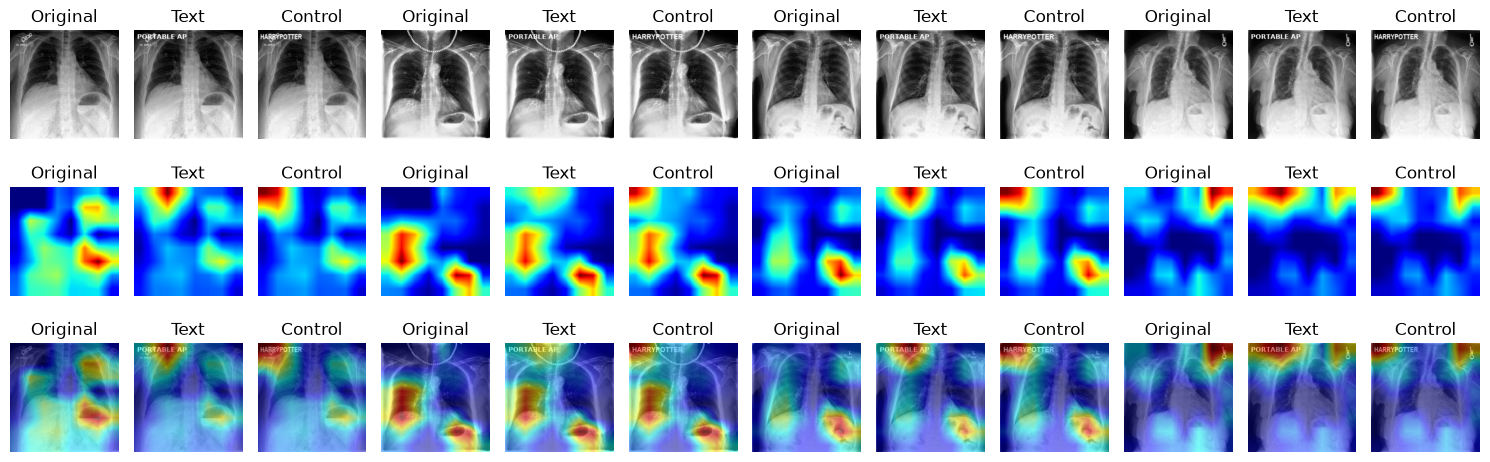

In [18]:
IMAGES3 = ["03_01", "03_02", "03_03", "03_04"]


fig, axes = plt.subplots(3, 12, figsize=(15, 5))

for ax in axes.flat:
    ax.axis("off")

col_n = 0
# Input tensor: shape [1, 3, H, W]
for j, img in enumerate(IMAGES3):
    image = Image.open("images/03_text_shortcut/" + img + "_original.jpg").convert('RGB')
    image_text = Image.open("images/03_text_shortcut/" + img + "_text.png").convert('RGB')
    control = add_control_text(image)

    x_original = preprocess(image)
    x_control = preprocess(control)
    x_text = preprocess(image_text)

    # Unnormalized RGB image for visualization
    rgb_img = np.asarray(
        image.resize((256, 256), Image.Resampling.BILINEAR),
        dtype=np.float32
    ) / 255.0

    rgb_control = np.asarray(
            control.resize((256, 256), Image.Resampling.BILINEAR),
            dtype=np.float32
        ) / 255.0

    rgb_text = np.asarray(
            image_text.resize((256, 256), Image.Resampling.BILINEAR),
            dtype=np.float32
        ) / 255.0

    axes[0,col_n].imshow(rgb_img)
    axes[0,col_n].set_title("Original")

    axes[0,col_n+1].imshow(rgb_text)
    axes[0,col_n+1].set_title("Text")

    axes[0,col_n+2].imshow(rgb_control)
    axes[0,col_n+2].set_title("Control")

    model = models['Atelectasis']
    model.eval()

    # Select the final DenseNet block
    target_layers = [model.features.denseblock4]

    # Generate Grad-CAM
    with GradCAM(model=model,  target_layers=target_layers) as cam:

        grayscale_cam_original = cam(input_tensor=x_original, targets=[BinaryClassifierOutputTarget(positive=True)])[0] # shape [H, W]
        grayscale_cam_text = cam(input_tensor=x_text, targets=[BinaryClassifierOutputTarget(positive=True)])[0] # shape [H, W]
        grayscale_cam_control = cam(input_tensor=x_control, targets=[BinaryClassifierOutputTarget(positive=True)])[0] # shape [H, W]

        visualization_original = show_cam_on_image(rgb_img, grayscale_cam_original, use_rgb=True)
        visualization_text = show_cam_on_image(rgb_text, grayscale_cam_text, use_rgb=True)
        visualization_control = show_cam_on_image(rgb_control, grayscale_cam_control, use_rgb=True)

        axes[1,col_n].imshow(grayscale_cam_original, cmap="jet")
        axes[1,col_n].set_title(f"Original")
        axes[2,col_n].imshow(visualization_original)
        axes[2,col_n].set_title(f"Original")

        axes[1,col_n+1].imshow(grayscale_cam_text, cmap="jet")
        axes[1,col_n+1].set_title(f"Text")
        axes[2,col_n+1].imshow(visualization_text)
        axes[2,col_n+1].set_title(f"Text")

        axes[1,col_n+2].imshow(grayscale_cam_control, cmap="jet")
        axes[1,col_n+2].set_title(f"Control")
        axes[2,col_n+2].imshow(visualization_control)
        axes[2,col_n+2].set_title(f"Control")

    col_n += 3
plt.tight_layout()
plt.show()

## 4. Heart vs lung occlusion

Resize to 256×256. Draw your own. Occlude the heart-region rectangle and an lung-region control avoiding the heart. Compare original/heart-hidden/lung-hidden Cardiomegaly scores and maps. Interpretation on what it does and what you onbserved.

In [19]:
def occlude_region(image, box):
    image = image.copy().convert("RGB")
    draw = ImageDraw.Draw(image)

    draw.rectangle(
        box,
        fill=(0, 0, 0)
    )

    return image

In [ ]:
image1 = Image.open("images/02_positive_negative/02_01_original.jpg").convert("RGB").resize((256, 256))
# Example coordinates only — adjust for your X-ray
heart_box1 = (80, 105, 200, 205)
lung_box1 = (50, 60, 120, 120)

heart_hidden1 = occlude_region(image1, heart_box1)
lung_hidden1 = occlude_region(image1, lung_box1)

(np.float64(-0.5), np.float64(255.5), np.float64(255.5), np.float64(-0.5))

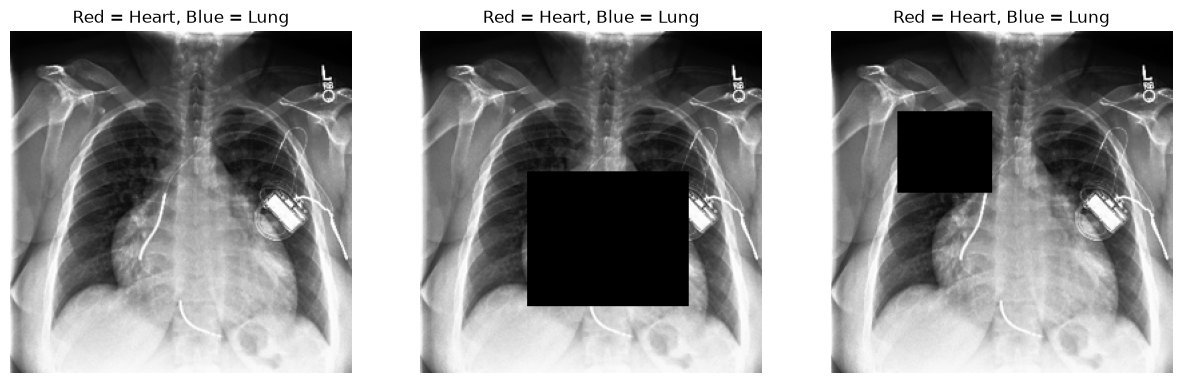

In [56]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(image1)
axes[0].set_title("Red = Heart, Blue = Lung")
axes[0].axis("off")

axes[1].imshow(heart_hidden1)
axes[1].set_title("Red = Heart, Blue = Lung")
axes[1].axis("off")

axes[2].imshow(lung_hidden1)
axes[2].set_title("Red = Heart, Blue = Lung")
axes[2].axis("off")

(np.float64(-0.5), np.float64(255.5), np.float64(255.5), np.float64(-0.5))

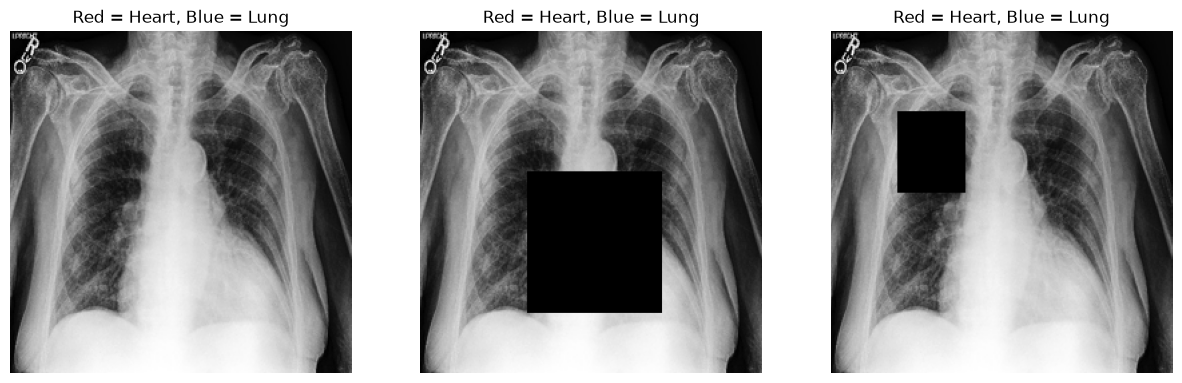

In [67]:
image2 = Image.open("images/02_positive_negative/02_02_original.jpg").convert("RGB").resize((256, 256))
# Example coordinates only — adjust for your X-ray
heart_box2 = (80, 105, 180, 210)
lung_box2 = (50, 60, 100, 120)

heart_hidden2 = occlude_region(image2, heart_box2)
lung_hidden2 = occlude_region(image2, lung_box2)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(image2)
axes[0].set_title("Red = Heart, Blue = Lung")
axes[0].axis("off")

axes[1].imshow(heart_hidden2)
axes[1].set_title("Red = Heart, Blue = Lung")
axes[1].axis("off")

axes[2].imshow(lung_hidden2)
axes[2].set_title("Red = Heart, Blue = Lung")
axes[2].axis("off")

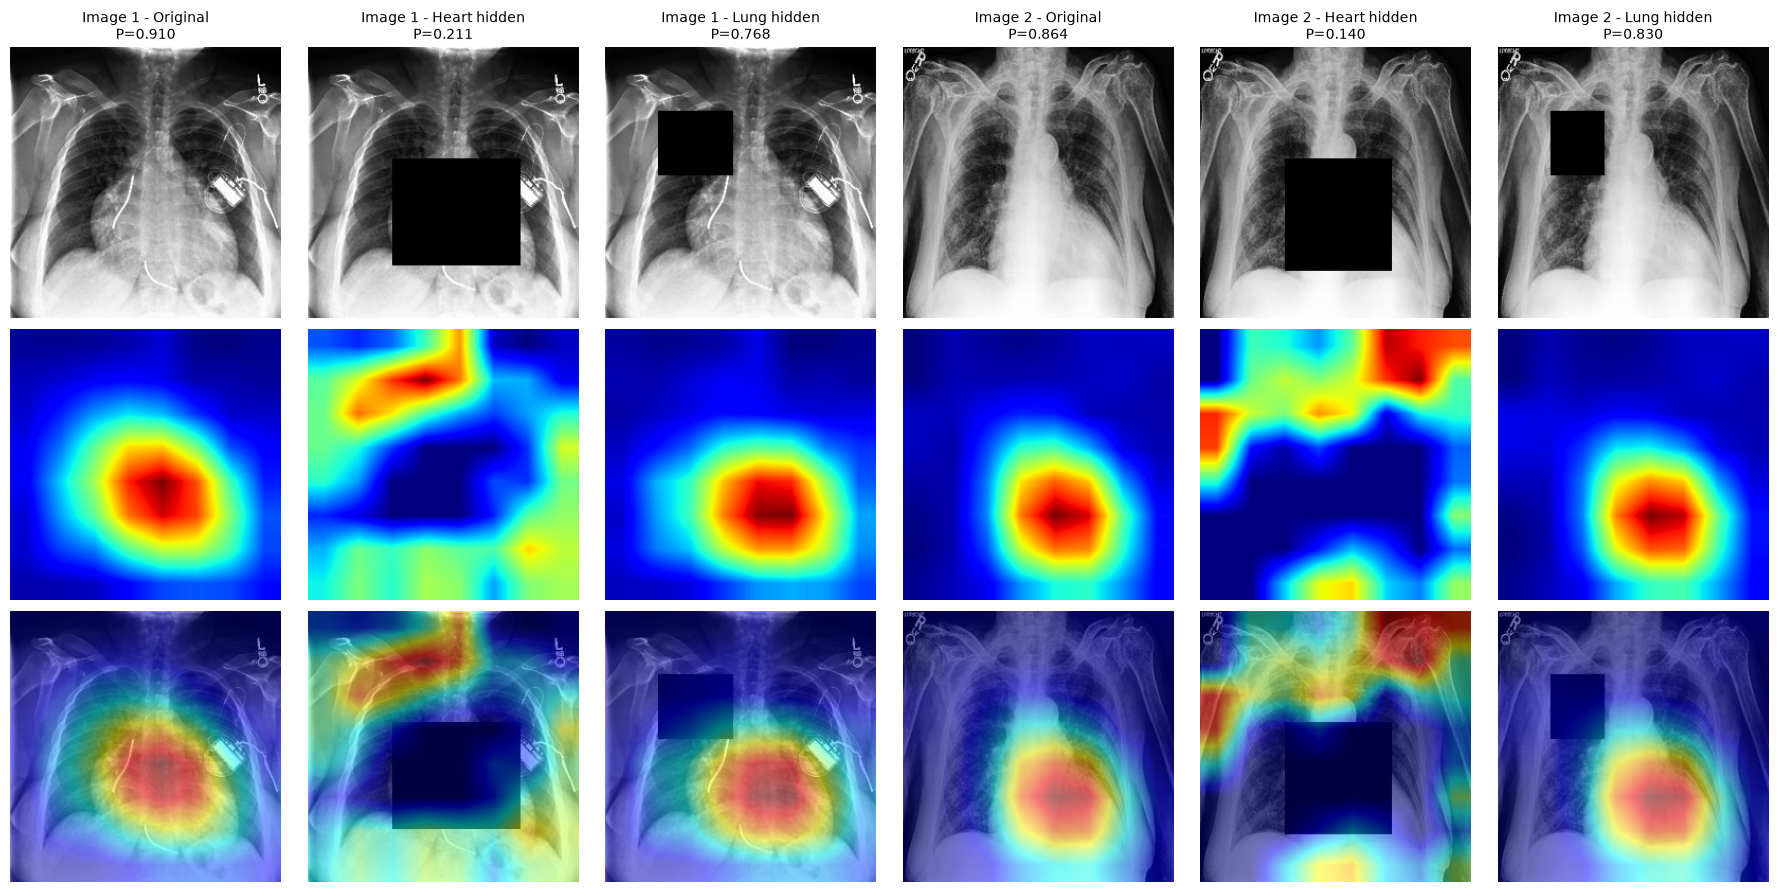

In [69]:
# Organize images and labels
images = [
    image1, heart_hidden1, lung_hidden1,
    image2, heart_hidden2, lung_hidden2
]

titles = [
    "Image 1 - Original",
    "Image 1 - Heart hidden",
    "Image 1 - Lung hidden",
    "Image 2 - Original",
    "Image 2 - Heart hidden",
    "Image 2 - Lung hidden"
]

# Load model
model = models["Cardiomegaly"]
model.eval()

device = next(model.parameters()).device
target_layers = [model.features.denseblock4]

# Create figure
fig, axes = plt.subplots(3, 6, figsize=(18, 9))

for ax in axes.flat:
    ax.axis("off")

# Initialize Grad-CAM once
with GradCAM(model=model, target_layers=target_layers) as cam:

    for i, (image, title) in enumerate(zip(images, titles)):

        # Preprocess image for model
        x = preprocess(image).to(device)

        # Convert PIL image to RGB NumPy array [0, 1]
        rgb_img = np.asarray(
            image.resize((256, 256)),
            dtype=np.float32
        ) / 255.0

        # Model prediction
        with torch.no_grad():
            logit = model(x).reshape(-1)[0]
            probability = torch.sigmoid(logit).item()

        # Generate Grad-CAM
        grayscale_cam = cam(
            input_tensor=x,
            targets=[BinaryClassifierOutputTarget(positive=True)]
        )[0]

        # Overlay heatmap on original image
        visualization = show_cam_on_image(
            rgb_img,
            grayscale_cam,
            use_rgb=True
        )

        # Row 1: Original / occluded image
        axes[0, i].imshow(rgb_img)
        axes[0, i].set_title(
            f"{title}\nP={probability:.3f}",
            fontsize=10
        )

        # Row 2: Grad-CAM heatmap
        axes[1, i].imshow(grayscale_cam, cmap="jet")

        # Row 3: Grad-CAM overlay
        axes[2, i].imshow(visualization)

plt.tight_layout()
plt.show()
